In [15]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

In [16]:
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

u = np.arange(rows) - crow
v = np.arange(cols) - ccol
U, V = np.meshgrid(u, v, indexing='ij')

D2 = U**2 + V**2
sigma = 30.0
H_lp = np.exp(-D2 / (2 * sigma**2))
H_hp = 1.0 - H_lp

dft_shift_filtered = dft_shift * H_hp[:, :, np.newaxis]
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

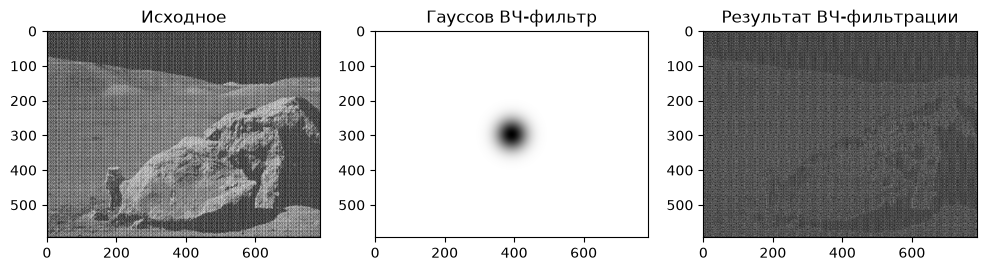

In [17]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное')
plt.subplot(1, 3, 2)
plt.imshow(H_hp, cmap='gray')
plt.title('Гауссов ВЧ-фильтр')
plt.subplot(1, 3, 3)
plt.imshow(img_back, cmap='gray')
plt.title('Результат ВЧ-фильтрации')
plt.show()

In [53]:
kernel_size = 5
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size**2)

rows, cols = img.shape
k_rows, k_cols = kernel.shape
pad_rows = rows + k_rows - 1
pad_cols = cols + k_cols - 1

img_padded = np.pad(img_float, ((0, pad_rows - rows), (0, pad_cols - cols)), mode='constant')
kernel_padded = np.pad(kernel, ((0, pad_rows - k_rows), (0, pad_cols - k_cols)), mode='constant')

dft_img = cv.dft(img_padded, flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)

real_part = dft_img[:, :, 0] * dft_kernel[:, :, 0] - dft_img[:, :, 1] * dft_kernel[:, :, 1]
imag_part = dft_img[:, :, 0] * dft_kernel[:, :, 1] + dft_img[:, :, 1] * dft_kernel[:, :, 0]

dft_product = np.dstack((real_part, imag_part))

img_back = cv.idft(dft_product)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

img_result = img_back[:rows, :cols]

img_spatial = cv.filter2D(img, -1, kernel)

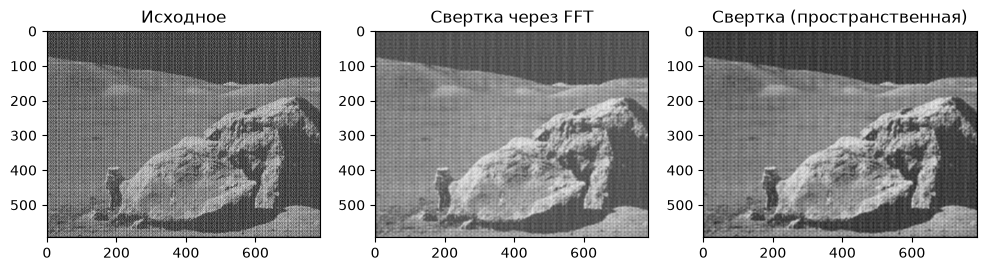

In [54]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное')
plt.subplot(1, 3, 2)
plt.imshow(img_result, cmap='gray')
plt.title('Свертка через FFT')
plt.subplot(1, 3, 3)
plt.imshow(img_spatial, cmap='gray')
plt.title('Свертка (пространственная)')
plt.show()

In [58]:
mask = np.ones((rows, cols), np.uint8)

magnitude = np.abs(dft_shift)

mag_no_center = magnitude.copy()
cv.circle(mag_no_center, (ccol, crow), radius=50, color=0, thickness=-1)

thresh_val = np.percentile(mag_no_center, 97.0) 
_, thresh_img = cv.threshold(mag_no_center, thresh_val, 255, cv.THRESH_BINARY)
thresh_img = thresh_img.astype(np.uint8)

contours, _ = cv.findContours(thresh_img[:, :, 0], cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

r = 15
for cnt in contours:
    M = cv.moments(cnt)
    if M["m00"] != 0:
        px = int(M["m10"] / M["m00"])
        py = int(M["m01"] / M["m00"])
        cv.circle(mask, (px, py), r, 0, -1)
        cv.circle(mask, (cols - px, rows - py), r, 0, -1)

dft_shift_filtered = dft_shift * mask[:, :, np.newaxis]

f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

img_back_normalized = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX)
img_back_normalized = np.uint8(img_back_normalized)


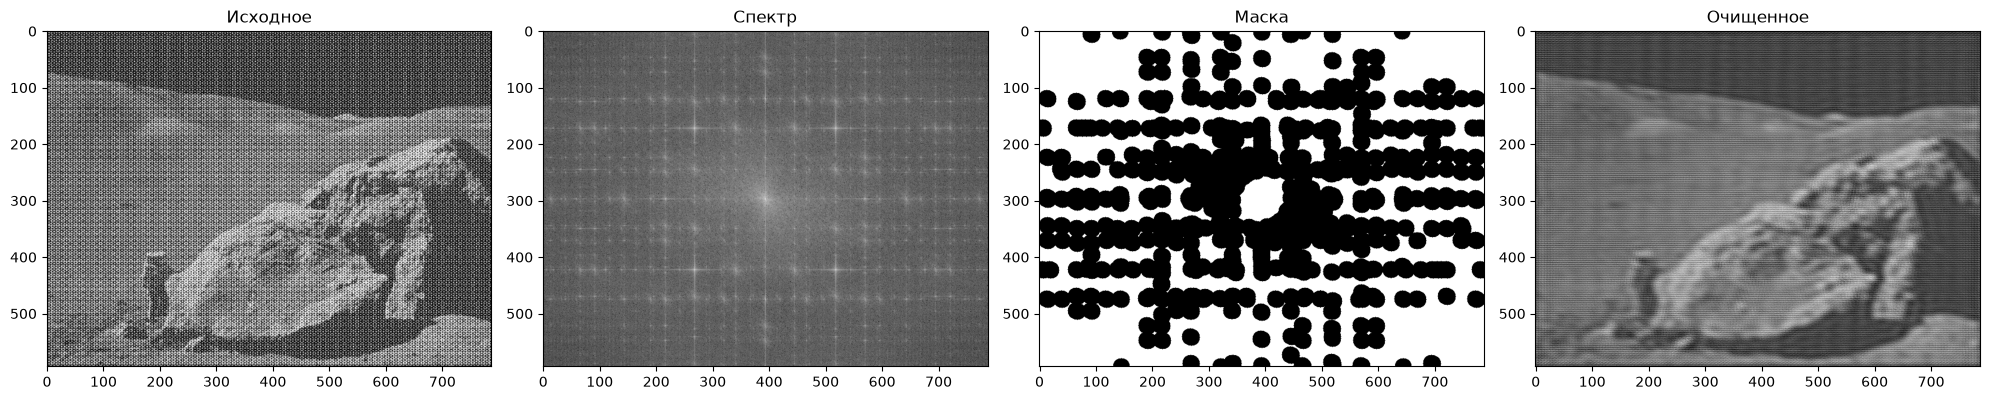

In [61]:
plt.figure(figsize=(20, 5)) 

plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное')

plt.subplot(1, 4, 2)
plt.imshow(20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1), cmap='gray')
plt.title('Спектр')

plt.subplot(1, 4, 3)
plt.imshow(mask * 255, cmap='gray') 
plt.title('Маска')

plt.subplot(1, 4, 4)
plt.imshow(img_back_normalized, cmap='gray')
plt.title('Очищенное')

plt.tight_layout() 
plt.show()